In [1]:
import torch, ultralytics
print("PyTorch:", torch.__version__, "| GPU:", torch.cuda.is_available())
print("Ultralytics:", ultralytics.__version__)

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
PyTorch: 2.14.1+cu130 | GPU: True
Ultralytics: 8.3.0


In [2]:
import os
import random
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image


In [3]:
data_path = "/app/data/raw/brain_tumor"
class_names = ["Glioma", "Meningioma", "No Tumor", "Pituitary"]
colors = ["red", "blue", "green", "orange"]

random.seed(42)

In [4]:
def show_image_with_boxes(image_path, label_path, ax):
    img = Image.open(image_path)
    width, height = img.size
    ax.imshow(img, cmap="gray")

    file = open(label_path)
    lines = file.read().strip().split("\n")
    file.close()

    for line in lines:
        values = line.split()
        class_id = int(values[0])
        x_center = float(values[1]) * width
        y_center = float(values[2]) * height
        box_width = float(values[3]) * width
        box_height = float(values[4]) * height

        x_left = x_center - box_width / 2
        y_top = y_center - box_height / 2

        rect = patches.Rectangle((x_left, y_top), box_width, box_height,
                                 linewidth=2, edgecolor=colors[class_id], facecolor="none")
        ax.add_patch(rect)
        ax.text(x_left, y_top - 5, class_names[class_id],
                color=colors[class_id], fontsize=10, weight="bold")

    ax.axis("off")

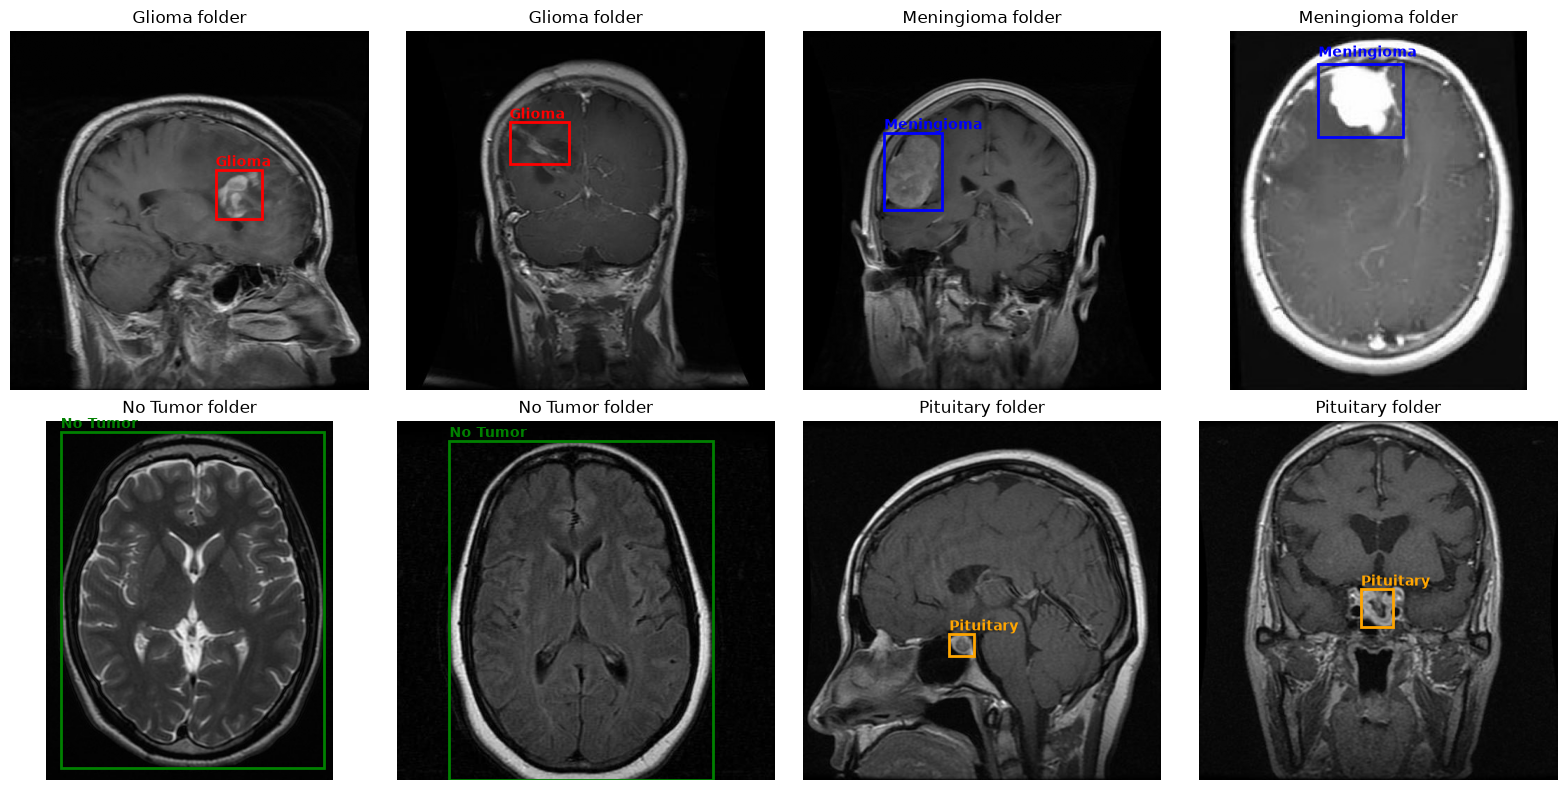

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
i = 0

for class_folder in class_names:
    images_path = os.path.join(data_path, "Train", class_folder, "images")
    labels_path = os.path.join(data_path, "Train", class_folder, "labels")

    image_files = os.listdir(images_path)
    chosen = random.sample(image_files, 2)

    for image_file in chosen:
        base_name = os.path.splitext(image_file)[0]
        label_file = base_name + ".txt"

        ax = axes[i // 4][i % 4]
        show_image_with_boxes(os.path.join(images_path, image_file),
                              os.path.join(labels_path, label_file), ax)
        ax.set_title(class_folder + " folder")
        i = i + 1

plt.tight_layout()
plt.savefig("/app/reports/detection_samples.png")
plt.show()

In [7]:
for class_folder in class_names:
    images_path = os.path.join(data_path, "Train", class_folder, "images")
    labels_path = os.path.join(data_path, "Train", class_folder, "labels")
    
    image_files = os.listdir(images_path)
    
    missing_labels = []
    
    for image_file in image_files:
        base_name = os.path.splitext(image_file)[0]
        label_file = base_name + ".txt"
        label_path = os.path.join(labels_path, label_file)
        if not os.path.exists(label_path):
            missing_labels.append(image_file)
            
    print(f"\nClass: {class_folder}")
    print(f"Total images: {len(image_files)}")
    print(f"Missing labels: {len(missing_labels)}")

    if len(missing_labels) > 0:
        print("Images without labels:")
        for image_file in missing_labels:
                    print(image_file)
    else:
        print("All images have corresponding labels!")


Class: Glioma
Total images: 1153
Missing labels: 0
All images have corresponding labels!

Class: Meningioma
Total images: 1449
Missing labels: 0
All images have corresponding labels!

Class: No Tumor
Total images: 711
Missing labels: 0
All images have corresponding labels!

Class: Pituitary
Total images: 1424
Missing labels: 0
All images have corresponding labels!


In [8]:
for split in ["Train", "Val"]:
    print("=====", split, "=====")

    for class_folder in class_names:
        images_path = os.path.join(data_path, split, class_folder, "images")
        labels_path = os.path.join(data_path, split, class_folder, "labels")

        image_files = os.listdir(images_path)
        label_files = os.listdir(labels_path)

        image_names = []
        for f in image_files:
            image_names.append(os.path.splitext(f)[0])

        label_names = []
        for f in label_files:
            label_names.append(os.path.splitext(f)[0])

        images_no_label = []
        for name in image_names:
            if name not in label_names:
                images_no_label.append(name)

        labels_no_image = []
        for name in label_names:
            if name not in image_names:
                labels_no_image.append(name)

        empty_labels = []
        for f in label_files:
            file = open(os.path.join(labels_path, f))
            content = file.read().strip()
            file.close()
            if content == "":
                empty_labels.append(f)

        print(class_folder)
        print("   images:", len(image_files), "| labels:", len(label_files))
        print("   images without label:", len(images_no_label))
        print("   labels without image:", len(labels_no_image))
        print("   empty label files:", len(empty_labels), empty_labels)

===== Train =====
Glioma
   images: 1153 | labels: 1153
   images without label: 0
   labels without image: 0
   empty label files: 0 []
Meningioma
   images: 1449 | labels: 1449
   images without label: 0
   labels without image: 0
   empty label files: 0 []
No Tumor
   images: 711 | labels: 711
   images without label: 0
   labels without image: 0
   empty label files: 0 []
Pituitary
   images: 1424 | labels: 1424
   images without label: 0
   labels without image: 0
   empty label files: 0 []
===== Val =====
Glioma
   images: 136 | labels: 136
   images without label: 0
   labels without image: 0
   empty label files: 1 ['gg (342).txt']
Meningioma
   images: 140 | labels: 140
   images without label: 0
   labels without image: 0
   empty label files: 0 []
No Tumor
   images: 100 | labels: 100
   images without label: 2
   labels without image: 2
   empty label files: 0 []
Pituitary
   images: 136 | labels: 136
   images without label: 0
   labels without image: 0
   empty label file

In [9]:
problems = 0

for split in ["Train", "Val"]:
    for class_folder in class_names:
        images_path = os.path.join(data_path, split, class_folder, "images")
        labels_path = os.path.join(data_path, split, class_folder, "labels")

        image_names = [os.path.splitext(f)[0] for f in os.listdir(images_path)]
        label_files = os.listdir(labels_path)
        label_names = [os.path.splitext(f)[0] for f in label_files]

        for name in image_names:
            if name not in label_names:
                print(split, class_folder, "-> image without label:", name)
                problems = problems + 1

        for name in label_names:
            if name not in image_names:
                print(split, class_folder, "-> label without image:", name)
                problems = problems + 1

        for f in label_files:
            file = open(os.path.join(labels_path, f))
            content = file.read().strip()
            file.close()
            if content == "":
                print(split, class_folder, "-> EMPTY label file:", f)
                problems = problems + 1

print("Total problems found:", problems)

Val Glioma -> EMPTY label file: gg (342).txt
Val No Tumor -> image without label: image(55)
Val No Tumor -> image without label: image(61)
Val No Tumor -> label without image: image(53)
Val No Tumor -> label without image: image(60)
Total problems found: 5


In [10]:
pairs = []
excluded = []

for split in ["Train", "Val"]:
    for class_folder in class_names:
        images_path = os.path.join(data_path, split, class_folder, "images")
        labels_path = os.path.join(data_path, split, class_folder, "labels")

        images = {}
        for f in os.listdir(images_path):
            images[os.path.splitext(f)[0]] = f
        labels = {}
        for f in os.listdir(labels_path):
            labels[os.path.splitext(f)[0]] = f

        for name in images:
            if name not in labels:
                excluded.append((split, class_folder, name, "image without label"))
                continue

            label_path = os.path.join(labels_path, labels[name])
            file = open(label_path)
            content = file.read().strip()
            file.close()
            if content == "":
                excluded.append((split, class_folder, name, "empty label"))
                continue

            pairs.append([os.path.join(images_path, images[name]), label_path, class_folder])

        for name in labels:
            if name not in images:
                excluded.append((split, class_folder, name, "label without image"))

print("Valid pairs:", len(pairs))
print("Excluded:", len(excluded))
for item in excluded:
    print("  ", item)

Valid pairs: 5246
Excluded: 5
   ('Val', 'Glioma', 'gg (342)', 'empty label')
   ('Val', 'No Tumor', 'image(55)', 'image without label')
   ('Val', 'No Tumor', 'image(61)', 'image without label')
   ('Val', 'No Tumor', 'image(53)', 'label without image')
   ('Val', 'No Tumor', 'image(60)', 'label without image')


In [ ]:
print(pairs[:5])

[['/app/data/raw/brain_tumor/Train/Glioma/images/gg (1).jpg', '/app/data/raw/brain_tumor/Train/Glioma/labels/gg (1).txt', 'Glioma'], ['/app/data/raw/brain_tumor/Train/Glioma/images/gg (103).jpg', '/app/data/raw/brain_tumor/Train/Glioma/labels/gg (103).txt', 'Glioma'], ['/app/data/raw/brain_tumor/Train/Glioma/images/gg (104).jpg', '/app/data/raw/brain_tumor/Train/Glioma/labels/gg (104).txt', 'Glioma'], ['/app/data/raw/brain_tumor/Train/Glioma/images/gg (105).jpg', '/app/data/raw/brain_tumor/Train/Glioma/labels/gg (105).txt', 'Glioma'], ['/app/data/raw/brain_tumor/Train/Glioma/images/gg (106).jpg', '/app/data/raw/brain_tumor/Train/Glioma/labels/gg (106).txt', 'Glioma']]


In [ ]:
# [
#     [
#         '/app/data/raw/brain_tumor/Train/Glioma/images/gg (1).jpg', 
#         '/app/data/raw/brain_tumor/Train/Glioma/labels/gg (1).txt', 
#         'Glioma'
#      ], 
#     [
#         '/app/data/raw/brain_tumor/Train/Glioma/images/gg (103).jpg', 
#         '/app/data/raw/brain_tumor/Train/Glioma/labels/gg (103).txt', 
#         'Glioma'
#     ]
# ]

In [12]:
from sklearn.model_selection import train_test_split

classes = [p[2] for p in pairs]

train_pairs, temp_pairs = train_test_split(
    pairs, test_size=0.30, stratify=classes, random_state=42)

temp_classes = [p[2] for p in temp_pairs]
val_pairs, test_pairs = train_test_split(
    temp_pairs, test_size=0.50, stratify=temp_classes, random_state=42)

print(len(train_pairs), len(val_pairs), len(test_pairs))

3672 787 787


In [13]:
import shutil

out_path = "/app/data/processed/detection"
sets = {"train": train_pairs, "valid": val_pairs, "test": test_pairs}

counter = 0
for set_name in sets:
    os.makedirs(os.path.join(out_path, "images", set_name), exist_ok=True)
    os.makedirs(os.path.join(out_path, "labels", set_name), exist_ok=True)

    for image_path, label_path, class_folder in sets[set_name]:
        counter = counter + 1
        new_name = class_folder.replace(" ", "") + "_" + str(counter).zfill(4)
        extension = os.path.splitext(image_path)[1]

        shutil.copy(image_path, os.path.join(out_path, "images", set_name, new_name + extension))
        shutil.copy(label_path, os.path.join(out_path, "labels", set_name, new_name + ".txt"))

In [14]:
for set_name in ["train", "valid", "test"]:
    n_images = len(os.listdir(os.path.join(out_path, "images", set_name)))
    n_labels = len(os.listdir(os.path.join(out_path, "labels", set_name)))
    print(set_name, "-> images:", n_images, "| labels:", n_labels)

train -> images: 3672 | labels: 3672
valid -> images: 787 | labels: 787
test -> images: 787 | labels: 787


In [15]:
out_path = "/app/data/processed/detection"
problems = []
class_count = {}

for set_name in ["train", "valid", "test"]:
    class_count[set_name] = {0: 0, 1: 0, 2: 0, 3: 0}
    labels_folder = os.path.join(out_path, "labels", set_name)

    for label_file in os.listdir(labels_folder):
        file = open(os.path.join(labels_folder, label_file))
        lines = file.read().strip().split("\n")
        file.close()

        for line in lines:
            values = line.split()

            if len(values) != 5:
                problems.append((set_name, label_file, "not 5 values"))
                continue

            try:
                class_id = int(values[0])
                numbers = [float(v) for v in values[1:]]
            except:
                problems.append((set_name, label_file, "not numbers"))
                continue

            if class_id not in [0, 1, 2, 3]:
                problems.append((set_name, label_file, "bad class id " + str(class_id)))
                continue

            for number in numbers:
                if number < 0 or number > 1:
                    problems.append((set_name, label_file, "value outside 0-1"))
                    break

            if numbers[2] <= 0 or numbers[3] <= 0:
                problems.append((set_name, label_file, "box with zero size"))

            class_count[set_name][class_id] = class_count[set_name][class_id] + 1

print("Problems found:", len(problems))
for p in problems[:20]:
    print("  ", p)

print()
for set_name in class_count:
    print(set_name, class_count[set_name])

Problems found: 0

train {0: 1059, 1: 1135, 2: 566, 3: 1352}
valid {0: 219, 1: 240, 2: 122, 3: 294}
test {0: 224, 1: 249, 2: 121, 3: 290}


In [16]:
class_names = ["Glioma", "Meningioma", "No Tumor", "Pituitary"]

text = "path: /app/data/processed/detection\n"
text = text + "train: images/train\n"
text = text + "val: images/valid\n"
text = text + "test: images/test\n"
text = text + "nc: 4\n"
text = text + "names: " + str(class_names) + "\n"

file = open("/app/data/processed/detection/data.yaml", "w")
file.write(text)
file.close()

print(text)

path: /app/data/processed/detection
train: images/train
val: images/valid
test: images/test
nc: 4
names: ['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']



In [17]:
from ultralytics import YOLO

model = YOLO("yolov8s.pt")

100%|██████████| 21.5M/21.5M [05:11<00:00, 72.5kB/s]


In [18]:
results = model.train(
    data="/app/data/processed/detection/data.yaml",
    epochs=50,
    patience=10,
    imgsz=640,
    batch=16,
    device=0,
    seed=42,
    project="/app/models/detection",
    name="yolov8s_run1",
    
    hsv_h=0.0, hsv_s=0.0, hsv_v=0.3,
    degrees=10, translate=0.1, scale=0.3,
    fliplr=0.5, flipud=0.0, mosaic=1.0
) 

New https://pypi.org/project/ultralytics/8.4.192 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.0 🚀 Python-3.11.18 torch-2.14.1+cu130 CUDA:0 (NVIDIA RTX 2000 Ada Generation Laptop GPU, 8188MiB)
engine/trainer: task=detect, mode=train, model=yolov8s.pt, data=/app/data/processed/detection/data.yaml, epochs=50, time=None, patience=10, batch=16, imgsz=640, save=True, save_period=-1, cache=False, device=0, workers=8, project=/app/models/detection, name=yolov8s_run1, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=42, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnostic_nms=False, cla

100%|██████████| 755k/755k [00:00<00:00, 2.49MB/s]


Overriding model.yaml nc=80 with nc=4

                   from  n    params  module                                       arguments                     
  0                  -1  1       928  ultralytics.nn.modules.conv.Conv             [3, 32, 3, 2]                 
  1                  -1  1     18560  ultralytics.nn.modules.conv.Conv             [32, 64, 3, 2]                
  2                  -1  1     29056  ultralytics.nn.modules.block.C2f             [64, 64, 1, True]             
  3                  -1  1     73984  ultralytics.nn.modules.conv.Conv             [64, 128, 3, 2]               
  4                  -1  2    197632  ultralytics.nn.modules.block.C2f             [128, 128, 2, True]           
  5                  -1  1    295424  ultralytics.nn.modules.conv.Conv             [128, 256, 3, 2]              
  6                  -1  2    788480  ultralytics.nn.modules.block.C2f             [256, 256, 2, True]           
  7                  -1  1   1180672  ultralytics

100%|██████████| 6.25M/6.25M [00:00<00:00, 15.5MB/s]


AMP: checks passed ✅


...

      50/50      4.05G      0.636     0.3036      0.992          8        640: 100%|██████████| 230/230 [02:05<00:00,  1.83it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 25/25 [00:15<00:00,  1.58it/s]

                   all        787        875       0.93      0.928       0.96      0.767



50 epochs completed in 2.613 hours.
Optimizer stripped from /app/models/detection/yolov8s_run1/weights/last.pt, 19.9MB
Optimizer stripped from /app/models/detection/yolov8s_run1/weights/best.pt, 19.9MB

Validating /app/models/detection/yolov8s_run1/weights/best.pt...
Ultralytics 8.3.0 🚀 Python-3.11.18 torch-2.14.1+cu130 CUDA:0 (NVIDIA RTX 2000 Ada Generation Laptop GPU, 8188MiB)
Model summary (fused): 186 layers, 9,829,212 parameters, 0 gradients, 23.3 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 25/25 [00:17<00:00,  1.43it/s]


                   all        787        875      0.945      0.914      0.961      0.769
                Glioma        194        219       0.91      0.829      0.917      0.716
            Meningioma        235        240      0.975      0.975      0.991      0.829
              No Tumor        122        122      0.976      0.992      0.995      0.829
             Pituitary        280        294       0.92      0.859      0.942      0.702
Speed: 0.4ms preprocess, 4.1ms inference, 0.0ms loss, 4.4ms postprocess per image
Results saved to /app/models/detection/yolov8s_run1
MLflow: results logged to runs/mlflow
MLflow: disable with 'yolo settings mlflow=False'


In [1]:
from ultralytics import YOLO

model = YOLO("/app/models/detection/yolov8s_run1/weights/best.pt")

metrics = model.val(
    data="/app/data/processed/detection/data.yaml",
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    project="/app/models/detection",
    name="test_eval")

print("Precision:     ", metrics.box.mp)
print("Recall:        ", metrics.box.mr)
print("mAP@0.5:       ", metrics.box.map50)
print("mAP@0.5:0.95:  ", metrics.box.map)

Ultralytics 8.3.0 🚀 Python-3.11.18 torch-2.14.1+cu130 CUDA:0 (NVIDIA RTX 2000 Ada Generation Laptop GPU, 8188MiB)
Model summary (fused): 186 layers, 9,829,212 parameters, 0 gradients, 23.3 GFLOPs


val: Scanning /app/data/processed/detection/labels/test... 787 images, 0 backgrounds, 0 corrupt: 100%|██████████| 787/787 [00:04<00:00, 177.20it/s]


val: New cache created: /app/data/processed/detection/labels/test.cache


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 50/50 [00:12<00:00,  4.07it/s]


                   all        787        884      0.931      0.917       0.95      0.753
                Glioma        193        224      0.879      0.839      0.898      0.667
            Meningioma        238        249      0.979       0.96      0.981       0.82
              No Tumor        121        121      0.991          1      0.995      0.814
             Pituitary        276        290      0.875      0.869      0.926       0.71
Speed: 0.8ms preprocess, 7.4ms inference, 0.0ms loss, 2.0ms postprocess per image
Results saved to /app/models/detection/test_eval
Precision:      0.9312628590201668
Recall:         0.9170226472392031
mAP@0.5:        0.9502383491515412
mAP@0.5:0.95:   0.7526403305580538


In [2]:
for i in range(len(metrics.box.ap_class_index)):
    class_id = metrics.box.ap_class_index[i]
    print(model.names[class_id],
          "| P:", round(metrics.box.p[i], 3),
          "| R:", round(metrics.box.r[i], 3),
          "| mAP50:", round(metrics.box.ap50[i], 3),
          "| mAP50-95:", round(metrics.box.ap[i], 3))

Glioma | P: 0.879 | R: 0.839 | mAP50: 0.898 | mAP50-95: 0.667
Meningioma | P: 0.979 | R: 0.96 | mAP50: 0.981 | mAP50-95: 0.82
No Tumor | P: 0.991 | R: 1.0 | mAP50: 0.995 | mAP50-95: 0.814
Pituitary | P: 0.875 | R: 0.869 | mAP50: 0.926 | mAP50-95: 0.71


In [3]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("/app/models/detection/yolov8s_run1/results.csv")
df.columns = df.columns.str.strip()

plt.figure(figsize=(14, 4))

plt.subplot(1, 3, 1)
plt.plot(df["epoch"], df["train/box_loss"], label="train")
plt.plot(df["epoch"], df["val/box_loss"], label="validation")
plt.title("Box loss")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 3, 2)
plt.plot(df["epoch"], df["train/cls_loss"], label="train")
plt.plot(df["epoch"], df["val/cls_loss"], label="validation")
plt.title("Class loss")
plt.xlabel("Epoch")
plt.legend()

plt.subplot(1, 3, 3)
plt.plot(df["epoch"], df["metrics/mAP50(B)"], label="mAP@0.5")
plt.plot(df["epoch"], df["metrics/mAP50-95(B)"], label="mAP@0.5:0.95")
plt.title("Validation mAP")
plt.xlabel("Epoch")
plt.legend()

plt.tight_layout()
plt.savefig("/app/reports/detection_training_curves.png")
plt.show()

<Figure size 1400x400 with 3 Axes>

In [5]:
import shutil
import os
shutil.copy("/app/models/detection/yolov8s_run1/weights/best.pt",
            "/app/models/detection/best.pt")
shutil.copy("/app/data/processed/detection/data.yaml",
            "/app/models/detection/data.yaml")

print(os.listdir("/app/models/detection"))

['best.pt', 'data.yaml', 'test_eval', 'yolov8s_run1']
